# 05 — Escenarios gerenciales para abastecimiento

Este cuaderno compara decisiones hipotéticas con los artefactos CSV que ya produjo el proyecto. **No vuelve a entrenar modelos, no lee ni modifica la base SQLite y no crea órdenes.** La referencia es el plan guardado; los cambios de demanda, el descuento de liquidación y el costo de mantener inventario son supuestos explícitos, no resultados realizados.

## Alcance y reglas de lectura

- El inventario físico (`EXIST_W11`) y las unidades en tránsito (`TRANSITO`) se muestran por separado; la posición de inventario es su suma y no implica disponibilidad física inmediata.
- El valor en bodega se calcula solo para existencias físicas con costo unitario conocido. Costos ausentes quedan sin valorizar; nunca se convierten en costo cero.
- La inactividad en las últimas 26 columnas semanales es un **proxy histórico**, no la edad del lote. El archivo no contiene fecha de recepción por SKU y su ventana puede no coincidir con la fecha del snapshot de existencias.
- No existe una clasificación autorizada de repuestos. Candidatos sospechosos quedan protegidos y cualquier otro SKU requiere una lista blanca aprobada por una persona. La lista comienza vacía; la liquidación aprobada es cero por defecto.
- El valor de compra evitado, los ingresos de liquidación, la pérdida frente al costo contable, el costo de mantenimiento y la rotación son estimaciones condicionales; no son ahorros, ventas, inventario envejecido ni mejoras de servicio observadas.

Los parámetros `LEAD_WEEKS`, `REVIEW_WEEKS`, `DEMAND_STRESS`, `DEMAND_DECLINE`, `LIQUIDATION_DISCOUNT` y `ANNUAL_HOLDING_RATE` se presentan para revisión gerencial antes de cualquier decisión.

In [1]:
from __future__ import annotations

import math
import re
from pathlib import Path

import numpy as np
import pandas as pd

LEAD_WEEKS = 13
REVIEW_WEEKS = 4
DEMAND_STRESS = 1.20
DEMAND_DECLINE = 0.75
LIQUIDATION_DISCOUNT = 0.30
ANNUAL_HOLDING_RATE = 0.20
INACTIVITY_WEEKS = 26

SCENARIO_DEFINITIONS = [
    {"name": "Referencia: plan archivado", "kind": "artefacto observado"},
    {"name": "Estrés de demanda +20%", "kind": "supuesto"},
    {"name": "Caída de demanda -25%", "kind": "supuesto"},
    {"name": "Sin descontar tránsito", "kind": "contrafactual"},
    {"name": "Revisión de inactividad y liquidación condicionada", "kind": "supuesto con aprobación humana"},
]

_SPARE_OR_TECHNICAL = re.compile(
    r"repuesto|refacci[oó]n|spare|parts?|filtro|filter|maintenance|mantenimiento|"
    r"repair|gasket|seal|oring|o-ring|tornillo|screw|tool|herramienta|bomba|pump|"
    r"m[aá]quina|equipo|fixture|utiler[ií]a|replacement|service",
    flags=re.IGNORECASE,
)


def validate_plan(plan: pd.DataFrame) -> pd.DataFrame:
    required = {
        "SKU", "DESCRIPCION", "mu", "sigma", "z_aplicado", "EXIST_W11",
        "TRANSITO", "FACTOR", "COSTO_UNITARIO",
    }
    missing = sorted(required - set(plan.columns))
    if missing:
        raise ValueError(f"Faltan columnas requeridas en el plan: {missing}")
    result = plan.copy()
    result["SKU"] = result["SKU"].fillna("").astype(str).str.strip()
    if result["SKU"].eq("").any():
        raise ValueError("El plan contiene SKU vacíos.")
    duplicates = result.loc[result["SKU"].duplicated(keep=False), "SKU"].unique()
    if len(duplicates):
        raise ValueError(f"El plan contiene SKU duplicados: {duplicates[:10].tolist()}")
    for column in ("mu", "sigma", "z_aplicado", "EXIST_W11", "TRANSITO", "FACTOR"):
        numeric = pd.to_numeric(result[column], errors="coerce")
        if numeric.isna().any() or not np.isfinite(numeric.to_numpy(dtype=float)).all():
            raise ValueError(f"{column} debe contener valores numéricos finitos.")
        if (numeric < 0).any():
            raise ValueError(f"{column} no puede contener cantidades negativas.")
        result[column] = numeric.astype(float)
    if (result["FACTOR"] <= 0).any():
        raise ValueError("FACTOR debe ser mayor que cero para redondear cajas.")
    cost = pd.to_numeric(result["COSTO_UNITARIO"], errors="coerce")
    invalid_cost = cost.notna() & ~np.isfinite(cost.to_numpy(dtype=float))
    if invalid_cost.any() or (cost.dropna() < 0).any():
        raise ValueError("COSTO_UNITARIO debe ser finito y no negativo; los faltantes se conservan sin valorizar.")
    result["COSTO_UNITARIO"] = cost.astype(float)
    result["DESCRIPCION"] = result["DESCRIPCION"].fillna("").astype(str).str.strip()
    result["IP"] = result["EXIST_W11"] + result["TRANSITO"]
    result["valor_bodega_usd"] = result["EXIST_W11"] * result["COSTO_UNITARIO"]
    return result


def replenishment_scenario(
    plan: pd.DataFrame,
    demand_multiplier: float,
    include_transit: bool = True,
    lead_weeks: int = LEAD_WEEKS,
    review_weeks: int = REVIEW_WEEKS,
) -> pd.DataFrame:
    if not np.isfinite(demand_multiplier) or demand_multiplier < 0:
        raise ValueError("El multiplicador de demanda debe ser finito y no negativo.")
    if lead_weeks <= 0 or review_weeks < 0:
        raise ValueError("El tránsito debe ser positivo y la revisión no negativa.")
    result = validate_plan(plan)
    mu = result["mu"] * demand_multiplier
    sigma = result["sigma"] * demand_multiplier
    buffer = result["z_aplicado"] * sigma * math.sqrt(lead_weeks)
    result["rop_scenario"] = mu * lead_weeks + buffer
    result["target_scenario"] = mu * (lead_weeks + review_weeks) + buffer
    result["physical_units"] = result["EXIST_W11"]
    result["transit_units"] = result["TRANSITO"]
    result["available_units"] = result["IP"] if include_transit else result["physical_units"]
    result["physical_only_units"] = result["physical_units"]
    gap = (result["target_scenario"] - result["available_units"]).clip(lower=0)
    reorder_now = result["available_units"] <= result["rop_scenario"]
    result["order_cases"] = np.where(
        reorder_now, np.ceil(gap / result["FACTOR"]), 0
    ).astype(int)
    result["order_units"] = result["order_cases"] * result["FACTOR"]
    result["order_value_usd"] = result["order_units"] * result["COSTO_UNITARIO"]
    physical_gap = (result["target_scenario"] - result["physical_only_units"]).clip(lower=0)
    physical_reorder_now = result["physical_only_units"] <= result["rop_scenario"]
    result["physical_only_order_units"] = np.where(
        physical_reorder_now, np.ceil(physical_gap / result["FACTOR"]), 0
    ).astype(int) * result["FACTOR"]
    result["physical_only_order_value_usd"] = result["physical_only_order_units"] * result["COSTO_UNITARIO"]
    result["coverage_weeks"] = np.where(mu > 0, result["available_units"] / mu, np.nan)
    result["weeks_until_rop"] = np.where(
        mu > 0, ((result["available_units"] - result["rop_scenario"]) / mu).clip(lower=0), np.nan
    )
    return result


def liquidation_review(
    plan: pd.DataFrame,
    history: pd.DataFrame,
    approved_skus: set[str] | None = None,
    inactivity_weeks: int = INACTIVITY_WEEKS,
    discount: float = LIQUIDATION_DISCOUNT,
    annual_holding_rate: float = ANNUAL_HOLDING_RATE,
) -> pd.DataFrame:
    if inactivity_weeks <= 0 or not 0 <= discount < 1 or annual_holding_rate < 0:
        raise ValueError("Revise la ventana, el descuento y la tasa anual de mantenimiento.")
    weekly_columns = sorted(
        [column for column in history.columns if re.fullmatch(r"wk\d+", str(column))],
        key=lambda column: int(str(column)[2:]),
    )
    if len(weekly_columns) < inactivity_weeks:
        raise ValueError(f"Se requieren al menos {inactivity_weeks} columnas semanales.")
    history = history.copy()
    history["SKU"] = history["SKU"].fillna("").astype(str).str.strip()
    if history["SKU"].eq("").any() or history["SKU"].duplicated().any():
        raise ValueError("El histórico debe contener un SKU único y no vacío por fila.")
    recent = weekly_columns[-inactivity_weeks:]
    values = history[recent].apply(pd.to_numeric, errors="coerce")
    finite = pd.DataFrame(
        np.isfinite(values.to_numpy(dtype=float)), index=values.index, columns=values.columns
    )
    activity = history[["SKU"]].copy()
    activity["activity_known"] = (
        values.notna().all(axis=1) & finite.all(axis=1) & values.ge(0).all(axis=1)
    ).to_numpy()
    activity["inactivity_proxy"] = (
        activity["activity_known"] & values.fillna(0).sum(axis=1).eq(0).to_numpy()
    )
    result = validate_plan(plan).merge(activity, on="SKU", how="left", validate="one_to_one")
    result["activity_known"] = result["activity_known"].fillna(False).astype(bool)
    result["inactivity_proxy"] = result["inactivity_proxy"].fillna(False).astype(bool)
    classification_text = (
        result["DESCRIPCION"].fillna("") + " " + result.get("PROVEEDOR", pd.Series("", index=result.index)).fillna("").astype(str)
    )
    result["suspected_spare"] = classification_text.str.contains(_SPARE_OR_TECHNICAL, na=False)
    result["review_candidate"] = result["activity_known"] & result["inactivity_proxy"] & (result["EXIST_W11"] > 0)
    approved_skus = {str(sku).strip() for sku in (approved_skus or set())}
    result["whitelist_approved"] = result["SKU"].isin(approved_skus)
    result["approved_for_reviewed_release"] = (
        result["review_candidate"] & result["activity_known"] & ~result["suspected_spare"]
        & result["whitelist_approved"] & result["COSTO_UNITARIO"].notna()
    )
    result["approved_release_units"] = np.where(
        result["approved_for_reviewed_release"], result["EXIST_W11"], 0.0
    )
    result["review_candidate_book_value_usd"] = np.where(
        result["review_candidate"], result["valor_bodega_usd"], np.nan
    )
    result["hypothetical_proceeds_usd"] = (
        result["review_candidate_book_value_usd"] * (1 - discount)
    )
    result["hypothetical_loss_vs_book_usd"] = (
        result["review_candidate_book_value_usd"] - result["hypothetical_proceeds_usd"]
    )
    result["annual_carrying_cost_assumption_usd"] = (
        result["review_candidate_book_value_usd"] * annual_holding_rate
    )
    result["transit_units_excluded"] = result["TRANSITO"]
    result["decision_status"] = np.select(
        [~result["activity_known"], result["suspected_spare"], ~result["whitelist_approved"], result["approved_for_reviewed_release"]],
        ["Histórico no disponible: revisar", "Protegido: repuesto/utilería técnica probable", "Requiere clasificación y aprobación humana", "Elegible bajo lista blanca; validar decisión"],
        default="Sin candidato de inactividad; no liquidar por este escenario",
    )
    return result


## 1. Carga reproducible y línea base

Se leen únicamente `historico_semanal.csv`, las partes CSV del plan, `segmentos_sku_csv` no es necesario para esta revisión, y las métricas guardadas. La fecha de modificación ayuda a identificar los artefactos locales; no sustituye un número de versión o una fecha de corte certificada.

In [2]:
def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    candidates = [current, *current.parents]
    for candidate in candidates:
        if (candidate / "data" / "plan_reabastecimiento_csv").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró data/plan_reabastecimiento_csv desde el directorio actual.")


ROOT = find_project_root()
DATA = ROOT / "data"
PLAN_FILES = sorted((DATA / "plan_reabastecimiento_csv").glob("part-*.csv"))
if not PLAN_FILES:
    raise FileNotFoundError("No hay partes CSV del plan de reabastecimiento.")
PLAN_RAW = pd.concat(
    [pd.read_csv(path, dtype={"SKU": str}) for path in PLAN_FILES],
    ignore_index=True,
)
PLAN = validate_plan(PLAN_RAW)
HISTORY_PATH = DATA / "historico_semanal.csv"
HISTORY = pd.read_csv(HISTORY_PATH, dtype={"SKU": str})
METRICS_PATH = DATA / "metricas_modelos.csv"
MODEL_METRICS = pd.read_csv(METRICS_PATH) if METRICS_PATH.is_file() else pd.DataFrame()
WEEK_COLUMNS = sorted(
    [column for column in HISTORY.columns if re.fullmatch(r"wk\d+", str(column))],
    key=lambda column: int(str(column)[2:]),
)
COVERAGE = pd.DataFrame(
    [{
        "SKUs_en_plan": len(PLAN),
        "SKUs_con_costo_conocido": int(PLAN["COSTO_UNITARIO"].notna().sum()),
        "SKUs_sin_costo": int(PLAN["COSTO_UNITARIO"].isna().sum()),
        "unidades_fisicas_sin_valorizar": float(PLAN.loc[PLAN["COSTO_UNITARIO"].isna(), "EXIST_W11"].sum()),
        "semanas_historicas_indexadas": len(WEEK_COLUMNS),
        "archivos_parte_plan": len(PLAN_FILES),
    }]
)

BASE = replenishment_scenario(PLAN, 1.0, include_transit=True)
STRESS = replenishment_scenario(PLAN, DEMAND_STRESS, include_transit=True)
DECLINE = replenishment_scenario(PLAN, DEMAND_DECLINE, include_transit=True)
WITHOUT_TRANSIT = replenishment_scenario(PLAN, 1.0, include_transit=False)
REVIEW = liquidation_review(PLAN, HISTORY)
print(f"Registros excluidos del proxy de inactividad por historia incompleta, negativa o no finita: {int((~REVIEW['activity_known']).sum())} SKU.")

def total_known_cost(frame: pd.DataFrame, quantity_column: str, cost_column: str = "COSTO_UNITARIO") -> float:
    known = frame[cost_column].notna()
    return float((frame.loc[known, quantity_column] * frame.loc[known, cost_column]).sum())


ARCHIVED_UNITS = pd.to_numeric(PLAN_RAW.get("cantidad_unid", 0), errors="coerce").fillna(0)
ARCHIVED_VALUE = pd.to_numeric(PLAN_RAW.get("valor_pedido_usd", 0), errors="coerce").fillna(0)
BASELINE_VALUE = total_known_cost(BASE, "order_units")
BASELINE_UNITS = float(BASE["order_units"].sum())
CANDIDATE_PROXY_UNITS = float(REVIEW.loc[REVIEW["review_candidate"], "EXIST_W11"].sum())
TRANSIT_EXTRA_UNITS = float((WITHOUT_TRANSIT["order_units"] - BASE["order_units"]).clip(lower=0).sum())
TRANSIT_EXTRA_VALUE = total_known_cost(
    WITHOUT_TRANSIT.assign(order_units=(WITHOUT_TRANSIT["order_units"] - BASE["order_units"]).clip(lower=0)),
    "order_units",
)

artifact_time = max(path.stat().st_mtime for path in PLAN_FILES)
artifact_utc = pd.Timestamp(artifact_time, unit="s", tz="UTC")
print(f"Raíz detectada: {ROOT}")
print(f"Plan: {len(PLAN)} SKU | {len(PLAN_FILES)} parte(s) CSV | última modificación observada: {artifact_utc}")
print(f"Histórico: {len(HISTORY)} SKU y {len(WEEK_COLUMNS)} columnas semanales indexadas; ventana de inactividad: {INACTIVITY_WEEKS}")
print("Los datos no se reentrenan ni escriben; solo se generan tablas y figuras de escenario.")
display(COVERAGE)
if not MODEL_METRICS.empty:
    display(MODEL_METRICS)

scenario_summary = pd.DataFrame([
    {
        "escenario": SCENARIO_DEFINITIONS[0]["name"],
        "tipo": "Plan guardado; propuesta, no compra realizada",
        "unidades_sugeridas": float(ARCHIVED_UNITS.sum()),
        "valor_plan_guardado_usd": float(ARCHIVED_VALUE.sum()),
        "valor_recalculado_con_costos_conocidos_usd": BASELINE_VALUE,
    },
    {
        "escenario": SCENARIO_DEFINITIONS[1]["name"],
        "tipo": "Supuesto; demanda y dispersión escalan 20%",
        "unidades_sugeridas": float(STRESS["order_units"].sum()),
        "valor_plan_guardado_usd": np.nan,
        "valor_recalculado_con_costos_conocidos_usd": total_known_cost(STRESS, "order_units"),
    },
    {
        "escenario": SCENARIO_DEFINITIONS[2]["name"],
        "tipo": "Supuesto; demanda y dispersión escalan 25% a la baja",
        "unidades_sugeridas": float(DECLINE["order_units"].sum()),
        "valor_plan_guardado_usd": np.nan,
        "valor_recalculado_con_costos_conocidos_usd": total_known_cost(DECLINE, "order_units"),
    },
    {
        "escenario": SCENARIO_DEFINITIONS[3]["name"],
        "tipo": "Contrafactual; pedido calculado con stock físico solamente",
        "unidades_sugeridas": float(WITHOUT_TRANSIT["order_units"].sum()),
        "valor_plan_guardado_usd": np.nan,
        "valor_recalculado_con_costos_conocidos_usd": total_known_cost(WITHOUT_TRANSIT, "order_units"),
    },
    {
        "escenario": SCENARIO_DEFINITIONS[4]["name"],
        "tipo": "Proxy; aprobación y lista blanca vacías por defecto",
        "unidades_sugeridas": CANDIDATE_PROXY_UNITS,
        "valor_plan_guardado_usd": np.nan,
        "valor_recalculado_con_costos_conocidos_usd": 0.0,
    },
])
scenario_summary["diferencia_vs_referencia_usd"] = np.where(
    scenario_summary["escenario"] == SCENARIO_DEFINITIONS[4]["name"], np.nan,
    scenario_summary["valor_recalculado_con_costos_conocidos_usd"] - BASELINE_VALUE,
)
print("Resumen comparativo: el costo es un compromiso teórico a costo unitario, no ahorro ni gasto realizado.")
display(scenario_summary.round(2))

archived_units_numeric = pd.to_numeric(PLAN_RAW.get("cantidad_unid", 0), errors="coerce").fillna(0).to_numpy(dtype=float)
baseline_unit_mismatch = int((~np.isclose(archived_units_numeric, BASE["order_units"].to_numpy(dtype=float))).sum())
print(f"SKU cuya cantidad archivada difiere del recálculo con los parámetros visibles: {baseline_unit_mismatch} de {len(PLAN)}")

position_table = BASE[["SKU", "DESCRIPCION", "physical_units", "transit_units", "IP", "mu", "rop_scenario", "coverage_weeks", "order_units", "order_value_usd"]].copy()
position_table["unidades_adicionales_si_se_ignora_transito"] = (
    WITHOUT_TRANSIT["order_units"].to_numpy() - BASE["order_units"].to_numpy()
).clip(min=0)
print("Mayor diferencia de compra hipotética por no descontar el tránsito (no ahorro realizado):")
display(position_table.sort_values("unidades_adicionales_si_se_ignora_transito", ascending=False).head(10).round(2))

book = PLAN[["SKU", "DESCRIPCION", "EXIST_W11", "TRANSITO", "COSTO_UNITARIO", "valor_bodega_usd"]].copy()
book = book.rename(columns={"EXIST_W11": "existencia_fisica_unidades", "TRANSITO": "transito_no_incluido_en_bodega"})
book_total = float(book["valor_bodega_usd"].sum(skipna=True))
print(f"Valor de existencias físicas a costo unitario conocido: ${book_total:,.2f}; no incluye tránsito.")
print("Concentración monetaria del inventario físico: solo unidades con costo conocido.")
display(book.sort_values("valor_bodega_usd", ascending=False).head(10).round(2))

print("Revisión de inactividad: candidato no equivale a artículo obsoleto ni a permiso de liquidación.")
review_columns = [
    "SKU", "DESCRIPCION", "physical_units", "transit_units", "COSTO_UNITARIO",
    "inactivity_proxy", "suspected_spare", "review_candidate", "approved_release_units",
    "review_candidate_book_value_usd", "hypothetical_proceeds_usd",
    "hypothetical_loss_vs_book_usd", "annual_carrying_cost_assumption_usd", "decision_status",
]
review_display = REVIEW.rename(columns={"EXIST_W11": "physical_units", "TRANSITO": "transit_units"})
display(review_display.loc[review_display["review_candidate"], review_columns].sort_values(
    "review_candidate_book_value_usd", ascending=False, na_position="last"
).head(20).round(2))
candidate_cost_known = REVIEW["review_candidate_book_value_usd"].notna()
candidate_book_value = float(REVIEW.loc[candidate_cost_known, "review_candidate_book_value_usd"].sum())
candidate_units = float(REVIEW.loc[REVIEW["review_candidate"], "EXIST_W11"].sum())
approved_release = float(REVIEW["approved_release_units"].sum())
print(f"Candidatos proxy: {int(REVIEW['review_candidate'].sum())} SKU / {candidate_units:,.0f} unidades físicas.")
print(f"Valor conocido de candidatos: ${candidate_book_value:,.2f}; unidades no valorizadas: {int((REVIEW['review_candidate'] & REVIEW['COSTO_UNITARIO'].isna()).sum())} SKU.")
print(f"Liberación autorizada por esta corrida: {approved_release:,.0f} unidades y $0.00 en ingresos; lista blanca no provista.")
print(f"Ingreso potencial SOLO si se aprueba cada SKU y se realiza la venta, con descuento supuesto {LIQUIDATION_DISCOUNT:.0%}: ${candidate_book_value * (1 - LIQUIDATION_DISCOUNT):,.2f}.")
print(f"Pérdida hipotética frente al valor en libros al descuento supuesto: ${candidate_book_value * LIQUIDATION_DISCOUNT:,.2f}; no es pérdida contable reconocida.")
print(f"Costo anual de mantenimiento estimado al {ANNUAL_HOLDING_RATE:.0%}: ${candidate_book_value * ANNUAL_HOLDING_RATE:,.2f}; requiere validación financiera.")

sensitivity = pd.DataFrame([
    {"descuento_supuestos": discount, "tasa_mantenimiento_anual_supuest": rate,
     "ingreso_potencial_condicional_usd": candidate_book_value * (1 - discount),
     "perdida_vs_libros_hipotetica_usd": candidate_book_value * discount,
     "costo_mantenimiento_anual_estimado_usd": candidate_book_value * rate}
    for discount in (0.10, 0.30, 0.50)
    for rate in (0.10, 0.20, 0.30)
])
print("Sensibilidad a descuento y costo de mantenimiento: escenarios para decisión, no parámetros contables aprobados.")
display(sensitivity.round(2))

last_52 = WEEK_COLUMNS[-min(52, len(WEEK_COLUMNS)):]
demand_values = HISTORY[last_52].apply(pd.to_numeric, errors="coerce")
demand_finite = pd.DataFrame(
    np.isfinite(demand_values.to_numpy(dtype=float)), index=demand_values.index, columns=demand_values.columns
)
demand_known = demand_values.notna().all(axis=1) & demand_finite.all(axis=1) & demand_values.ge(0).all(axis=1)
history_value = HISTORY[["SKU"]].copy()
history_value["demand_52_units"] = demand_values.fillna(0).sum(axis=1).where(demand_known).to_numpy()
turnover = PLAN[["SKU", "COSTO_UNITARIO", "valor_bodega_usd"]].merge(history_value, on="SKU", how="left", validate="one_to_one")
turnover["demand_52_value_usd"] = turnover["demand_52_units"] * turnover["COSTO_UNITARIO"]
turnover["turnover_proxy_52_indexed_weeks"] = np.where(
    (turnover["valor_bodega_usd"] > 0) & turnover["demand_52_value_usd"].notna(),
    turnover["demand_52_value_usd"] / turnover["valor_bodega_usd"], np.nan,
)
known_turnover = turnover["turnover_proxy_52_indexed_weeks"].dropna()
print("Rotación proxy = demanda histórica valorizada de hasta 52 periodos indexados / valor del stock físico a costo unitario.")
print(f"SKUs con proxy calculable: {len(known_turnover)}; mediana: {known_turnover.median():.2f}x; SKUs excluidos por datos incompletos/negativos/no finitos: {int((~demand_known).sum())}." if len(known_turnover) else "Proxy no calculable con cobertura disponible.")
print("No es rotación contable: el snapshot y el periodo histórico pueden tener fechas distintas; no permite atribuir causalidad ni mejora de servicio.")


Registros excluidos del proxy de inactividad por historia incompleta, negativa o no finita: 9 SKU.
Raíz detectada: D:\Documents\bigdataproject
Plan: 436 SKU | 1 parte(s) CSV | última modificación observada: 2026-10-12 05:04:21.737799644+00:00
Histórico: 436 SKU y 174 columnas semanales indexadas; ventana de inactividad: 26
Los datos no se reentrenan ni escriben; solo se generan tablas y figuras de escenario.


,SKUs_en_plan,SKUs_con_costo_conocido,SKUs_sin_costo,unidades_fisicas_sin_valorizar,semanas_historicas_indexadas,archivos_parte_plan
0,436,436,0,0.0,174,1


,modelo,rmse,mae,r2
0,LinearRegression,5.66,1.56,0.867
1,RandomForest,5.37,1.46,0.880
2,GBT,6.13,1.60,0.844
3,BLEND (mezcla),5.39,1.49,0.880


Resumen comparativo: el costo es un compromiso teórico a costo unitario, no ahorro ni gasto realizado.


,escenario,tipo,unidades_sugeridas,valor_plan_guardado_usd,valor_recalculado_con_costos_conocidos_usd,diferencia_vs_referencia_usd
0,Referencia: plan archivado,"Plan guardado; propuesta, no compra realizada",20224.00,118289.35,117873.42,0.00
1,Estrés de demanda +20%,Supuesto; demanda y dispersión escalan 20%,26796.00,NaN,155931.43,38058.01
2,Caída de demanda -25%,Supuesto; demanda y dispersión escalan 25% a l...,11900.00,NaN,71330.88,-46542.54
3,Sin descontar tránsito,Contrafactual; pedido calculado con stock físi...,23756.00,NaN,134753.60,16880.18
4,Revisión de inactividad y liquidación condicio...,Proxy; aprobación y lista blanca vacías por de...,1685.05,NaN,0.00,NaN


...

Revisión de inactividad: candidato no equivale a artículo obsoleto ni a permiso de liquidación.


,SKU,DESCRIPCION,physical_units,transit_units,COSTO_UNITARIO,inactivity_proxy,suspected_spare,review_candidate,approved_release_units,review_candidate_book_value_usd,hypothetical_proceeds_usd,hypothetical_loss_vs_book_usd,annual_carrying_cost_assumption_usd,decision_status
349,11052225,VASO cold VENTI COMPOSTABLE 20/26 OZ (C10 PAQ4...,71.0,0.0,92.12,True,False,True,0.0,6540.52,4578.36,1962.16,1308.10,Requiere clasificación y aprobación humana
156,11134074,BOLSA DE PAPEL WARNING PARA PASTRY US (CAJA DE...,133.0,411.0,24.74,True,False,True,0.0,3290.42,2303.29,987.13,658.08,Requiere clasificación y aprobación humana
29,11069306,RAIL SYRUP CHAI WHITE MOCHA (KIT 5PCS),5.0,0.0,354.94,True,False,True,0.0,1774.70,1242.29,532.41,354.94,Requiere clasificación y aprobación humana
168,177803,DISPENSADOR PARA CREMA BATIDA,35.0,0.0,46.05,True,True,True,0.0,1611.75,1128.22,483.53,322.35,Protegido: repuesto/utilería técnica probable
222,154541,GARBAGE CAN BLACK DOME NEW 99,17.0,0.0,93.94,True,True,True,0.0,1596.98,1117.89,479.09,319.40,Protegido: repuesto/utilería técnica probable
294,11031084,DP BANNER STAND DK GREY,10.0,0.0,145.05,True,True,True,0.0,1450.50,1015.35,435.15,290.10,Protegido: repuesto/utilería técnica probable
85,11071343,TAPA ALTA 12OZ NITRO COLD BREW (Caja 6 Paq/85...,83.0,5.0,16.09,True,False,True,0.0,1335.47,934.83,400.64,267.09,Requiere clasificación y aprobación humana
150,11104273,BASKET FLOOR MED,11.0,0.0,81.65,True,True,True,0.0,898.15,628.71,269.45,179.63,Protegido: repuesto/utilería técnica probable
126,11031134,IMPULSE FIX SM SWEETS LS ( UNIDADES),7.0,0.0,113.81,True,True,True,0.0,796.67,557.67,239.00,159.33,Protegido: repuesto/utilería técnica probable
435,375401,DISPENSER SLEEVE HOT CUP 12 IN,12.0,0.0,46.10,True,True,True,0.0,553.20,387.24,165.96,110.64,Protegido: repuesto/utilería técnica probable


Candidatos proxy: 115 SKU / 1,685 unidades físicas.
Valor conocido de candidatos: $27,835.08; unidades no valorizadas: 0 SKU.
Liberación autorizada por esta corrida: 0 unidades y $0.00 en ingresos; lista blanca no provista.
Ingreso potencial SOLO si se aprueba cada SKU y se realiza la venta, con descuento supuesto 30%: $19,484.55.
Pérdida hipotética frente al valor en libros al descuento supuesto: $8,350.52; no es pérdida contable reconocida.
Costo anual de mantenimiento estimado al 20%: $5,567.02; requiere validación financiera.
Sensibilidad a descuento y costo de mantenimiento: escenarios para decisión, no parámetros contables aprobados.


,descuento_supuestos,tasa_mantenimiento_anual_supuest,ingreso_potencial_condicional_usd,perdida_vs_libros_hipotetica_usd,costo_mantenimiento_anual_estimado_usd
0,0.1,0.1,25051.57,2783.51,2783.51
1,0.1,0.2,25051.57,2783.51,5567.02
2,0.1,0.3,25051.57,2783.51,8350.52
3,0.3,0.1,19484.55,8350.52,2783.51
4,0.3,0.2,19484.55,8350.52,5567.02
5,0.3,0.3,19484.55,8350.52,8350.52
6,0.5,0.1,13917.54,13917.54,2783.51
7,0.5,0.2,13917.54,13917.54,5567.02
8,0.5,0.3,13917.54,13917.54,8350.52


Rotación proxy = demanda histórica valorizada de hasta 52 periodos indexados / valor del stock físico a costo unitario.
SKUs con proxy calculable: 238; mediana: 1.50x; SKUs excluidos por datos incompletos/negativos/no finitos: 13.
No es rotación contable: el snapshot y el periodo histórico pueden tener fechas distintas; no permite atribuir causalidad ni mejora de servicio.


## 2. Interpretación para una decisión

La tabla muestra por separado el valor archivado y el recálculo con los supuestos visibles. En cada sensibilidad solo se recomienda pedir cuando la posición de inventario del escenario está en o debajo del ROP; si se activa, se cubre hasta el objetivo de 13 semanas de tránsito más 4 de revisión y se redondea a cajas completas. Se valorizan únicamente costos conocidos. Doce de 436 SKU difieren en cantidad frente al archivo; concilie esa diferencia con el dueño del plan antes de adoptar el resultado. La opción «Sin descontar tránsito» es un contrafactual deliberadamente conservador que ilustra compra potencialmente duplicada, no una política recomendada ni ahorro capturado.

La tabla de inactividad presenta un conjunto para revisión, no una lista de artículos obsoletos. Los repuestos/utilería técnica probables se bloquean por texto; la ausencia de esas palabras no certifica que el artículo no sea repuesto. Solo una lista blanca validada permitiría calcular liberaciones condicionadas y, aun entonces, se requerirían aprobación comercial, evaluación de vida útil/condición, canal de venta y contabilización. El valor de salida se basa en una tasa de descuento hipotética sobre el valor conocido a costo; el valor en libros, ingreso y pérdida no son intercambiables.

El equipo de negocio debe validar el horizonte, los escenarios de demanda, la unidad logística, la fecha del inventario, los costos faltantes, la clasificación de repuestos, los descuentos y la tasa financiera antes de actuar. Para medir impacto se requiere una prueba controlada con datos de servicio, ventas no atendidas, compras aprobadas, recepciones, devoluciones y costo real, comparada contra un grupo de control.

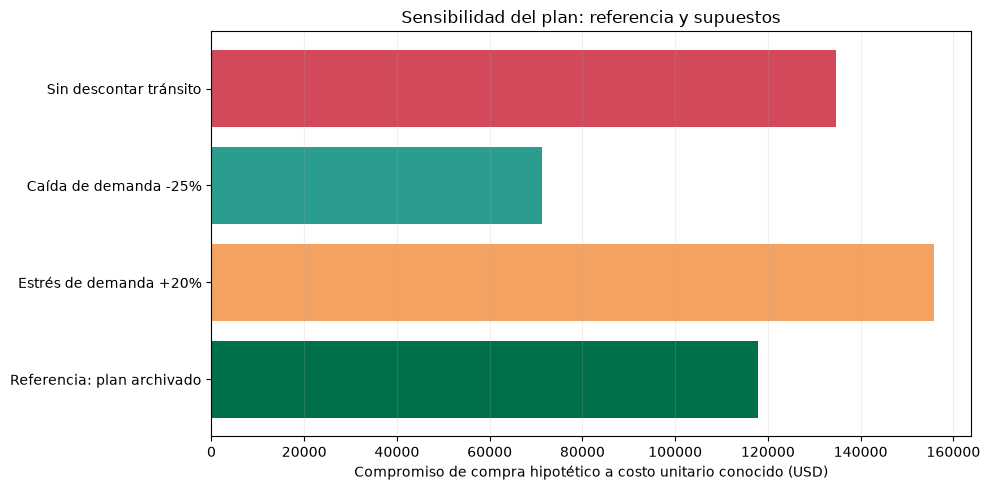

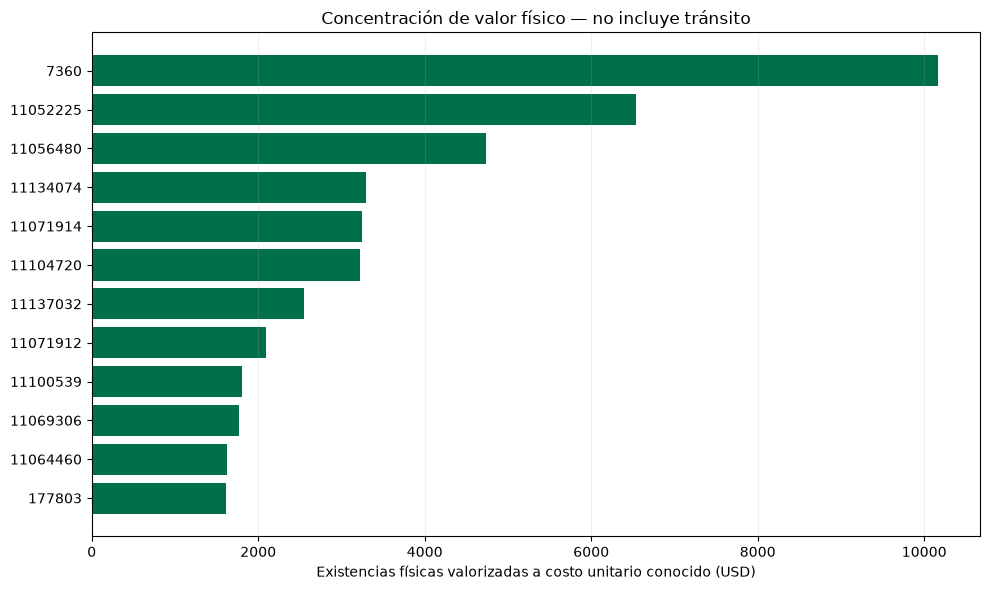

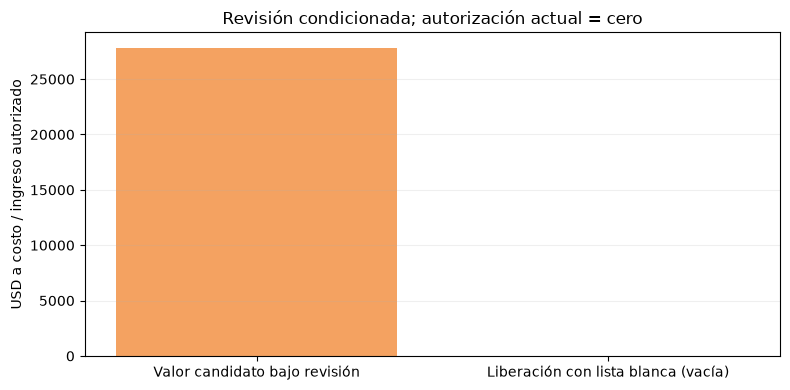

Figuras generadas localmente: D:\Documents\bigdataproject\informe\img\escenarios


In [3]:
import matplotlib.pyplot as plt

FIGURES_DIR = ROOT / "informe" / "img" / "escenarios"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

scenario_costs = scenario_summary.iloc[:4].copy()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(scenario_costs["escenario"], scenario_costs["valor_recalculado_con_costos_conocidos_usd"], color=["#00704A", "#f4a261", "#2a9d8f", "#d1495b"])
ax.set_xlabel("Compromiso de compra hipotético a costo unitario conocido (USD)")
ax.set_title("Sensibilidad del plan: referencia y supuestos")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_escenarios_compra.png", dpi=150, bbox_inches="tight")
plt.show()

top_book = book.dropna(subset=["valor_bodega_usd"]).nlargest(12, "valor_bodega_usd").sort_values("valor_bodega_usd")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_book["SKU"].astype(str), top_book["valor_bodega_usd"], color="#00704A")
ax.set_xlabel("Existencias físicas valorizadas a costo unitario conocido (USD)")
ax.set_title("Concentración de valor físico — no incluye tránsito")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_concentracion_inventario.png", dpi=150, bbox_inches="tight")
plt.show()

review_buckets = pd.DataFrame({
    "Estado": ["Valor candidato bajo revisión", "Liberación con lista blanca (vacía)"],
    "USD": [candidate_book_value, float(REVIEW["approved_release_units"].sum() * 0)],
})
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(review_buckets["Estado"], review_buckets["USD"], color=["#f4a261", "#00704A"])
ax.set_ylabel("USD a costo / ingreso autorizado")
ax.set_title("Revisión condicionada; autorización actual = cero")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_revision_liquidacion_condicionada.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Figuras generadas localmente: {FIGURES_DIR}")
